# Inventory Demand Forecast, 5 Car Parts, 51 Months

Goal: forecast the next 6 months of demand for a small set of parts. The data is real: the "car parts" dataset from Rob Hyndman's `expsmooth` R package, monthly sales of 2,674 car parts from January 1998 to March 2002, as published in the Monash Time Series Forecasting Repository (Zenodo, CC BY 4.0). I keep the 2,509 parts with no missing months and pick the 5 with the highest total sales.

Even the busiest parts sell only a few units a month, with many zero months. That's what real spare-parts demand looks like (intermittent demand), and it changes which methods make sense. I hold out the last 6 months and compare per-part SARIMA with two simple baselines: the training mean, and Croston's method, the classic approach for intermittent demand.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import io, urllib.request, zipfile
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX

OUT = Path('../../data/inventory'); OUT.mkdir(parents=True, exist_ok=True)

In [2]:
TSF = OUT / 'car_parts_dataset_with_missing_values.tsf'
if not TSF.exists():
    url = 'https://zenodo.org/api/records/4656022/files/car_parts_dataset_with_missing_values.zip/content'
    zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())).extractall(OUT)

series = {}
for line in TSF.read_text().splitlines():
    if line.startswith('T'):                      # data rows look like  T1:1998-01-01 00-00-00:0,0,2,...
        name, rest = line.split(':', 1)
        vals = [np.nan if v == '?' else float(v) for v in rest.split(':')[-1].split(',')]
        series[name] = vals
wide = pd.DataFrame(series, index=pd.date_range('1998-01-01', periods=51, freq='MS'))
complete = wide.loc[:, wide.notna().all()]
top5 = complete.sum().sort_values(ascending=False).index[:5]
df = complete[top5].reset_index(names='date').melt(id_vars='date', var_name='sku', value_name='demand')
print(f'parts: {wide.shape[1]}, complete: {complete.shape[1]}, using: {list(top5)}')
print(df.groupby('sku')['demand'].agg(total='sum', mean='mean', zero_share=lambda s: (s == 0).mean()).round(2))

parts: 2674, complete: 2509, using: ['T2674', 'T2673', 'T2672', 'T2671', 'T2670']
       total  mean  zero_share
sku                           
T2670   88.0  1.73        0.33
T2671   89.0  1.75        0.31
T2672   89.0  1.75        0.51
T2673   89.0  1.75        0.29
T2674   89.0  1.75        0.29


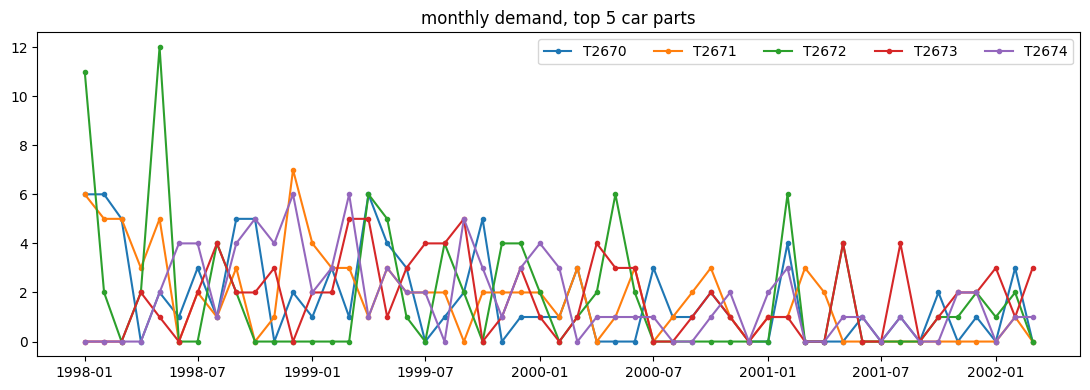

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
for sku, g in df.groupby('sku'):
    ax.plot(g['date'], g['demand'], marker='o', markersize=3, label=sku)
ax.set_title('monthly demand, top 5 car parts'); ax.legend(ncol=5)
plt.tight_layout(); plt.show()

## Fit one SARIMA per part, plus two baselines

SARIMA order is (1, 1, 1)(1, 1, 0, 12), fit on the first 45 months, which is fewer than 4 full seasonal cycles. Croston's method forecasts demand size and the interval between non-zero months separately (smoothing alpha = 0.1) and divides one by the other. I score everything with MAE on the 6 held-out months.

In [4]:
FORECAST_H = 6

def croston(y, alpha=0.1):
    """Classic Croston: smooth non-zero sizes and inter-demand intervals separately."""
    y = np.asarray(y, dtype=float)
    nz = np.where(y > 0)[0]
    if len(nz) == 0:
        return 0.0
    z, p, last = y[nz[0]], max(nz[0] + 1, 1), nz[0]
    for t in nz[1:]:
        z = z + alpha * (y[t] - z)
        p = p + alpha * ((t - last) - p)
        last = t
    return z / p

forecasts, scores = {}, []
for sku, g in df.groupby('sku'):
    s = g.set_index('date')['demand'].asfreq('MS')
    train, test = s.iloc[:-FORECAST_H], s.iloc[-FORECAST_H:]
    res = SARIMAX(train, order=(1,1,1), seasonal_order=(1,1,0,12)).fit(disp=False)
    fc = res.get_forecast(steps=FORECAST_H)
    forecasts[sku] = {
        'history': s,
        'mean':    fc.predicted_mean.clip(lower=0),
        'ci':      fc.conf_int(alpha=0.2).clip(lower=0),  # 80% interval
    }
    scores.append({
        'sku': sku,
        'SARIMA':  np.abs(test.values - forecasts[sku]['mean'].values).mean(),
        'mean':    np.abs(test.values - train.mean()).mean(),
        'Croston': np.abs(test.values - croston(train.values)).mean(),
    })
scores = pd.DataFrame(scores).set_index('sku')
scores.loc['average'] = scores.mean()
print('holdout MAE (units per month)')
print(scores.round(2))

holdout MAE (units per month)
         SARIMA  mean  Croston
sku                           
T2670      0.80  1.27     1.09
T2671      0.93  1.79     1.62
T2672      0.55  0.77     0.96
T2673      1.97  0.76     0.87
T2674      1.33  0.95     0.72
average    1.11  1.11     1.05


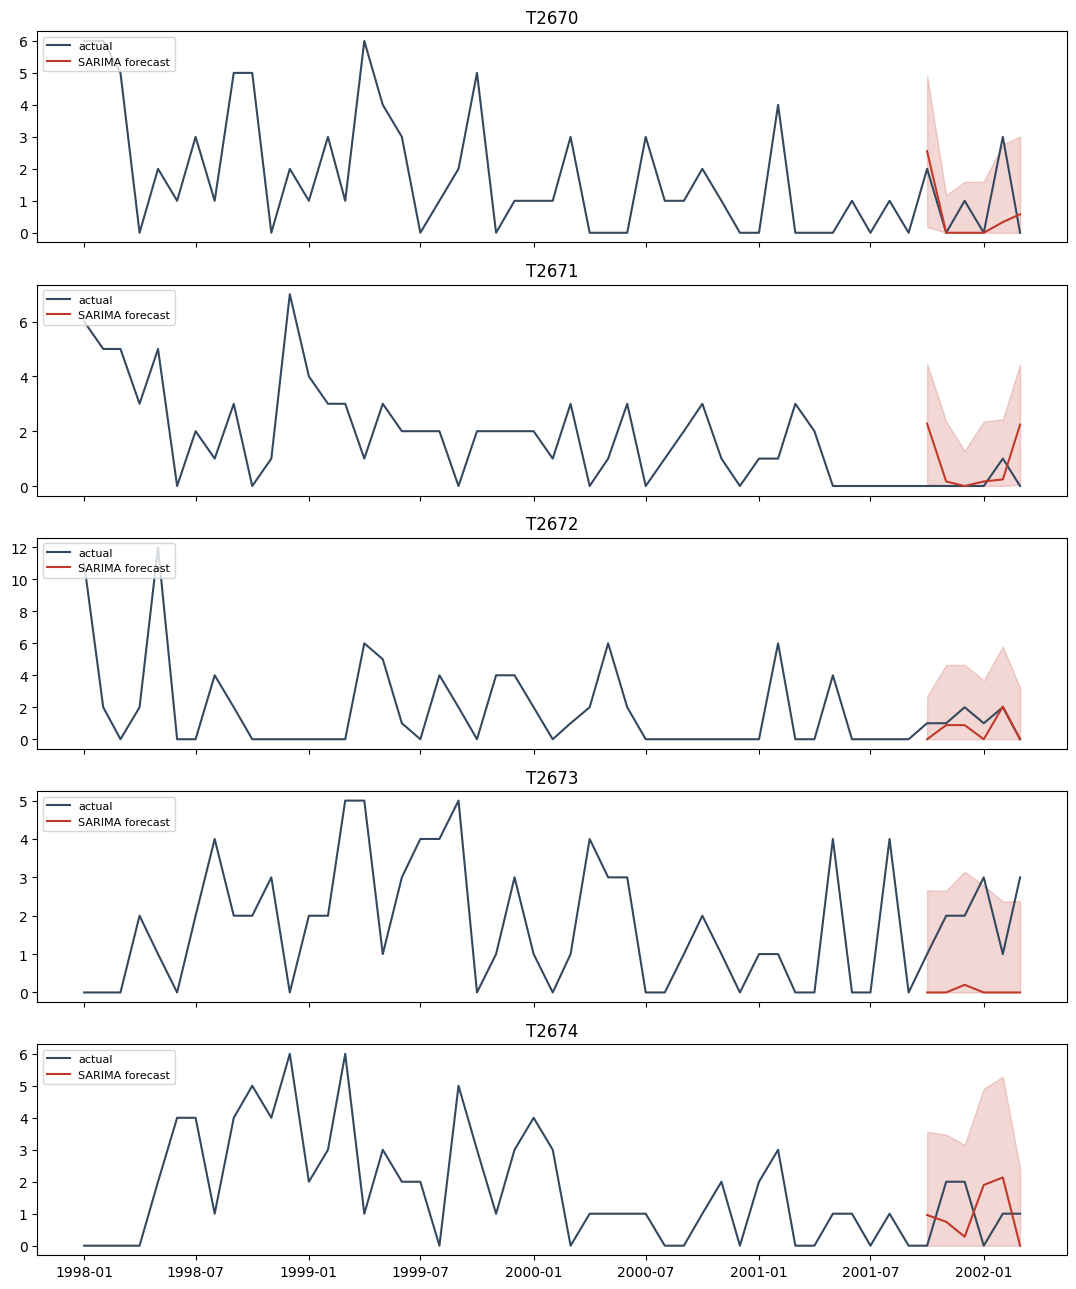

In [5]:
fig, axes = plt.subplots(len(forecasts), 1, figsize=(11, 2.6 * len(forecasts)), sharex=True)
for ax, (sku, f) in zip(axes, forecasts.items()):
    h = f['history']; m = f['mean']; ci = f['ci']
    ax.plot(h.index, h.values, label='actual', color='#34495e')
    ax.plot(m.index, m.values, label='SARIMA forecast', color='#c0392b')
    ax.fill_between(m.index, ci.iloc[:, 0], ci.iloc[:, 1], color='#c0392b', alpha=0.2)
    ax.set_title(sku); ax.legend(loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

In [6]:
# Roll the SARIMA forecasts for the holdout months into a planning table (rounded units).
out = []
for sku, f in forecasts.items():
    for d, v in zip(f['mean'].index, f['mean'].values):
        out.append({'sku': sku, 'month': d.strftime('%Y-%m'), 'forecast': round(float(v))})
plan = pd.DataFrame(out)
plan.pivot(index='month', columns='sku', values='forecast')

sku,T2670,T2671,T2672,T2673,T2674
month,,,,,
2001-10,3,2,0,0,1
2001-11,0,0,1,0,1
2001-12,0,0,1,0,0
2002-01,0,0,0,0,2
2002-02,0,0,2,0,2
2002-03,1,2,0,0,0


## Notes

- Averaged over the 5 parts, the three methods are basically tied on the 6 held-out months: Croston 1.05 units of MAE per month, SARIMA 1.11, and the plain training mean 1.11. SARIMA wins clearly on three parts and loses badly on T2673 (MAE 1.97 vs 0.76 for the mean). With demand of one or two units a month and a third of months at zero, there's very little seasonal pattern for SARIMA to find, and with fewer than 4 seasonal cycles it can latch onto noise.
- The planning table shows the practical problem with SARIMA here: it forecasts exact months with zero demand and others with 2-3 units, which looks precise but isn't. Croston gives one flat rate (about 1-2 units a month), which is what you'd actually use to set a reorder point.
- For intermittent demand, the forecast isn't the end product anyway. What matters for inventory is a quantile of total demand over the lead time, so I'd move to methods that give a demand distribution (bootstrapping, or the newer intermittent-demand models) and score them with a pinball loss instead of MAE.
- With 6 holdout months per part and only 5 parts, these MAE differences are well within noise. A fair comparison would use rolling origins across many more of the 2,509 complete series.